# Phase 3.5 — Balance the speaker-disjoint split proposal

**Objective:** Improve the Phase 3 proposal while keeping each audited speaker/session/audio component intact. The search considers decoded hours, recording month, age group, and clip duration. Gender is a light balancing term. Domain is shown as a diagnostic because its missing values strongly track recording month.

This notebook does **not** use model predictions or accuracy scores. It starts from the Phase 3 proposal and its exact-waveform hashes. It writes a new local proposal, then audits leakage again. The final freeze switch is off until you inspect the results.

A balanced split may be impossible with a few very large speaker groups. Report residual differences honestly; do not break components to improve a chart.

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import json
import math
import random

import numpy as np
import pandas as pd
from IPython.display import display

current = Path.cwd().resolve()
project = next(
    (folder for folder in (current, *current.parents)
     if (folder / "manifests/master_A_v1_1.parquet").is_file()),
    None,
)
if project is None:
    raise FileNotFoundError("Open this notebook from inside BTP.")

phase3_dir = project / "outputs/phase3_20261031_223422"
proposal_path = phase3_dir / "split_proposal.parquet"
audit_path = phase3_dir / "audit.json"
for path in (proposal_path, audit_path):
    if not path.is_file():
        raise FileNotFoundError(path)

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

source_sha256 = sha256_file(proposal_path)
phase3_audit = json.loads(audit_path.read_text(encoding="utf-8"))
data = pd.read_parquet(proposal_path)
required = {
    "sample_id", "component_id", "duration_decoded", "proposed_split",
    "train_only_effective", "speaker_group_id", "speaker_id", "speaker_id_raw",
    "recording_session_id", "exact_waveform_sha256", "transcript_phase2",
    "recording_month", "age_group", "gender", "domain", "speaker_status",
}
missing = required - set(data.columns)
if missing:
    raise ValueError(f"Phase 3 proposal lacks: {sorted(missing)}")
if data["sample_id"].isna().any() or data["sample_id"].duplicated().any():
    raise ValueError("Sample IDs must be present and unique.")
if data["exact_waveform_sha256"].isna().any():
    raise ValueError("Phase 3 exact-waveform hashes are incomplete.")
if phase3_audit.get("cross_split_overlap", {}).get("exact_waveform") != 0:
    raise ValueError("Phase 3 exact-waveform audit did not pass.")
if data.groupby("component_id")["proposed_split"].nunique().gt(1).any():
    raise ValueError("Phase 3 component was divided across splits.")

print("Phase 3 source:", proposal_path.relative_to(project))
print("Rows:", len(data), "components:", data["component_id"].nunique())
print("Source SHA-256:", source_sha256)
print("Original Phase 3 status:", phase3_audit.get("status"))

Phase 3 source: outputs/phase3_20261031_223422/split_proposal.parquet
Rows: 5044 components: 44
Source SHA-256: 6fc903dd53927da5eb623e67f062df091e5c9cc91ad29958945a9206ae8c4e92
Original Phase 3 status: proposed_not_frozen


## 1. Describe each indivisible component

The earlier exact-audio check found no duplicate waveforms and built 44 connected components. These components are the indivisible units in this notebook. A component containing a train-only clip remains in training. No waveform is re-decoded here.

In [2]:
component = (
    data.groupby("component_id", sort=True)
    .agg(
        clips=("sample_id", "size"),
        seconds=("duration_decoded", "sum"),
        train_only=("train_only_effective", "any"),
        old_split=("proposed_split", "first"),
    )
)
component["hours"] = component["seconds"] / 3600
component_ids = component.index.tolist()
total_hours = float(component["hours"].sum())
fixed = component["train_only"].to_numpy(dtype=bool)
split_names = ("train", "validation", "test")
split_code = {name: index for index, name in enumerate(split_names)}
old_assignment = component["old_split"].map(split_code).to_numpy(dtype=np.int8)
if pd.isna(component["old_split"]).any() or fixed[old_assignment != 0].any():
    raise ValueError("Invalid Phase 3 component assignment.")

print("Components:", len(component))
print("Fixed train-only components:", int(fixed.sum()))
print("Total decoded hours:", round(total_hours, 3))
display(component.sort_values("hours", ascending=False).head(12))

Components: 44
Fixed train-only components: 8
Total decoded hours: 14.625


,clips,seconds,train_only,old_split,hours
component_id,,,,,
A_000008,810,13159.969,False,train,3.655547
A_000036,657,8583.317,False,train,2.384255
A_000022,444,7174.473,False,train,1.992909
A_000001,377,3363.712,True,train,0.934364
A_000006,222,2655.212,True,train,0.737559
A_000005,226,2291.688,False,validation,0.636580
A_000067,218,1635.040,False,validation,0.454178
A_000296,135,1271.780,False,validation,0.353272
A_000163,100,937.240,True,train,0.260344


## 2. Prepare category vectors for a balanced search

Each component gets an hours vector for month, age, duration band and gender. The target distribution for each feature is the distribution of the complete 5,044-clip pool. The search tries to put a useful mix into each split while respecting the component boundaries.

Age and gender come from dataset metadata. `Unknown` remains its own category. Duration bins are 0.5–3, 3–10, 10–20 and 20–30 seconds.

In [3]:
features = data.copy()
features["_hours"] = features["duration_decoded"] / 3600
features["duration_band"] = pd.cut(
    features["duration_decoded"],
    bins=[0.0, 3.0, 10.0, 20.0, 30.000001],
    labels=["0.5–3 s", "3–10 s", "10–20 s", "20–30 s"],
    right=False,
)
if features["duration_band"].isna().any():
    raise ValueError("A candidate duration falls outside the planned bands.")

def hours_matrix(field):
    table = features.pivot_table(
        index="component_id", columns=field, values="_hours",
        aggfunc="sum", fill_value=0, observed=False,
    ).reindex(component_ids, fill_value=0)
    matrix = table.to_numpy(dtype=float)
    if not np.isclose(matrix.sum(), total_hours, atol=1e-7):
        raise ValueError(f"Category hours do not reconcile: {field}")
    return table.columns.tolist(), matrix

feature_info = {
    name: hours_matrix(name)
    for name in ("recording_month", "age_group", "duration_band", "gender")
}
for name, (labels, matrix) in feature_info.items():
    print(name, "categories:", list(map(str, labels)))

recording_month categories: ['2024-11', '2025-04', '2025-06', '2025-07', '2025-08', '2026-02']
age_group categories: ['18-30', '30-45', '45-60', '60+', 'Unknown']
duration_band categories: ['0.5–3 s', '3–10 s', '10–20 s', '20–30 s']
gender categories: ['Female', 'Male', 'Unknown']


## 3. Search whole-component assignments

This is a deterministic heuristic search, not a proof of the mathematically optimal split. It starts from the earlier proposal and several seeded alternatives. Its score penalizes deviations from 70%/15%/15% hours, differences in month/age/duration distributions, and held-out sets with fewer than four independent components.

The recorded weights make the proposal reproducible. Try changing weights only *before* seeing model results, and save every candidate proposal you compare.

In [4]:
TARGET_SHARE = np.array([0.70, 0.15, 0.15])
WEIGHTS = {
    "hours": 20.0,
    "recording_month": 1.5,
    "age_group": 1.0,
    "duration_band": 1.0,
    "gender": 0.3,
    "component_count": 0.7,
    "small_holdout": 2.0,
}
SEED = 20261031
RESTARTS = 8
STEPS_PER_RESTART = 4000
component_hours = component["hours"].to_numpy(dtype=float)

def assignment_score(assignment):
    hours = np.bincount(
        assignment, weights=component_hours, minlength=3
    ).astype(float)
    if (hours <= 0).any():
        return float("inf")
    score = WEIGHTS["hours"] * np.abs(
        hours / total_hours - TARGET_SHARE
    ).sum()
    for name, (_, matrix) in feature_info.items():
        overall = matrix.sum(axis=0) / total_hours
        by_split = np.stack([
            matrix[assignment == split].sum(axis=0) / hours[split]
            for split in range(3)
        ])
        score += WEIGHTS[name] * np.abs(by_split - overall).sum(axis=1).mean()
    group_counts = np.bincount(assignment, minlength=3)
    score += WEIGHTS["component_count"] * np.abs(
        group_counts / len(component) - TARGET_SHARE
    ).sum()
    score += WEIGHTS["small_holdout"] * sum(
        max(0, 4 - int(group_counts[split])) for split in (1, 2)
    )
    return float(score)

rng = random.Random(SEED)
movable = np.flatnonzero(~fixed)
best_assignment = old_assignment.copy()
best_score = assignment_score(best_assignment)
old_score = best_score

for restart in range(RESTARTS):
    if restart == 0:
        current_assignment = old_assignment.copy()
    else:
        current_assignment = np.zeros(len(component), dtype=np.int8)
        for index in movable:
            current_assignment[index] = rng.choices(
                [0, 1, 2], weights=[0.55, 0.225, 0.225]
            )[0]
    current_score = assignment_score(current_assignment)
    for step in range(STEPS_PER_RESTART):
        index = int(rng.choice(movable.tolist()))
        proposed = current_assignment.copy()
        proposed[index] = rng.choice(
            [code for code in (0, 1, 2) if code != int(proposed[index])]
        )
        proposed_score = assignment_score(proposed)
        temperature = 0.25 * (1 - step / STEPS_PER_RESTART) + 0.01
        if proposed_score < current_score or rng.random() < math.exp(
            (current_score - proposed_score) / temperature
        ):
            current_assignment, current_score = proposed, proposed_score
        if current_score < best_score:
            best_assignment, best_score = current_assignment.copy(), current_score

component["new_split"] = [split_names[int(code)] for code in best_assignment]
print("Old balance score:", round(old_score, 4))
print("New balance score:", round(best_score, 4))
print("Improvement:", round(old_score - best_score, 4))
display(component.groupby("new_split").agg(
    components=("clips", "size"), clips=("clips", "sum"),
    hours=("hours", "sum")
).reindex(split_names))

Old balance score: 3.4752
New balance score: 1.2581
Improvement: 2.2171


,components,clips,hours
new_split,,,
train,28,3055,10.234597
validation,6,542,2.203148
test,10,1447,2.186758


## 4. Compare original and revised proposals

Check both absolute hours and category *percentages*. The percentages reveal distribution differences even when train has more hours than validation or test. Domain and speaker status are shown as diagnostics, although they were not independently optimized in the search.

In [5]:
assignment_map = component["new_split"].to_dict()
data["revised_split"] = data["component_id"].map(assignment_map)
if data["revised_split"].isna().any():
    raise RuntimeError("Missing revised assignment.")

def split_summary(field):
    return (
        data.groupby(field)
        .agg(
            clips=("sample_id", "size"),
            hours=("duration_decoded", lambda values: values.sum() / 3600),
            components=("component_id", "nunique"),
            speaker_groups=("speaker_group_id", "nunique"),
            public_speakers=("speaker_id", "nunique"),
            median_clip_s=("duration_decoded", "median"),
        )
        .reindex(split_names, fill_value=0)
    )

old_summary = split_summary("proposed_split")
new_summary = split_summary("revised_split")
print("Original Phase 3 summary:")
display(old_summary.round(3))
print("Revised Phase 3.5 summary:")
display(new_summary.round(3))

def category_percent(split_field, category):
    hours = data.assign(_hours=data["duration_decoded"] / 3600).pivot_table(
        index=split_field, columns=category, values="_hours",
        aggfunc="sum", fill_value=0, observed=False,
    ).reindex(split_names, fill_value=0)
    return hours.div(hours.sum(axis=1).replace(0, np.nan), axis=0).mul(100)

for category in ("recording_month", "age_group", "duration_band",
                 "gender", "domain", "speaker_status"):
    if category == "duration_band":
        data["duration_band"] = features["duration_band"].to_numpy()
    print("\n", category, "percent of decoded hours (old / revised):")
    display(pd.concat({
        "Phase 3": category_percent("proposed_split", category).round(1),
        "Phase 3.5": category_percent("revised_split", category).round(1),
    }))

Original Phase 3 summary:


,clips,hours,components,speaker_groups,public_speakers,median_clip_s
proposed_split,,,,,,
train,2876,10.500,11,12,14,12.25
validation,1428,2.194,7,7,9,2.01
test,740,1.930,26,26,26,7.20


Revised Phase 3.5 summary:


,clips,hours,components,speaker_groups,public_speakers,median_clip_s
revised_split,,,,,,
train,3055,10.235,28,29,32,11.10
validation,542,2.203,6,6,6,13.70
test,1447,2.187,10,10,11,2.46



 recording_month percent of decoded hours (old / revised):


recording_month           2024-11  2025-04  2025-06  2025-07  2025-08  2026-02
          proposed_split                                                      
Phase 3   train               7.6     35.8     37.6      6.4     12.6      0.0
          validation         54.5     21.5     24.0      0.0      0.0      0.0
          test               96.4      0.3      0.0      0.0      0.0      3.3
Phase 3.5 train              24.0     30.9     31.4      4.4      8.7      0.6
          validation          9.5     27.2     33.1     10.2     20.0      0.0
          test               54.3     21.6     24.1      0.0      0.0      0.0

... (6 outputs left out)


 domain percent of decoded hours (old / revised):


domain                    Agriculture  Culture  Education  \
          proposed_split                                    
Phase 3   train                  28.6      5.5       34.4   
          validation             11.7      0.1       30.7   
          test                    0.3      3.3        0.0   
Phase 3.5 train                  24.1      5.4       29.4   
          validation             24.6      4.4       27.2   
          test                   11.7      0.1       30.8   

domain                    General-Oral-History  Healthcare  Lifecycle  \
          proposed_split                                                
Phase 3   train                            5.4         4.9        5.5   
          validation                       0.0         3.0        0.0   
          test                             0.0         0.0        0.0   
Phase 3.5 train                            3.4         4.1        3.6   
          validation                       9.8         4.1        9.2   
          test                             0.0         3.1        0.0   

domain                    Science-Technology  Sports  Unknown  
          proposed_split                                       
Phase 3   train                          7.3     1.0      7.6  
          validation                     0.0     0.0     54.5  
          test                           0.0     0.0     96.4  
Phase 3.5 train                          5.2     0.8     24.0  
          validation                    10.2     1.0      9.5  
          test                           0.0     0.0     54.3


 speaker_status percent of decoded hours (old / revised):


speaker_status            linked_to_pair  multi_person     ok  \
          proposed_split                                        
Phase 3   train                     15.9           3.4   76.5   
          validation                 0.0           0.0  100.0   
          test                       0.0           0.0  100.0   
Phase 3.5 train                     16.3           3.5   75.9   
          validation                 0.0           0.0  100.0   
          test                       0.0           0.0  100.0   

speaker_status            uncertain_identity  
          proposed_split                      
Phase 3   train                          4.2  
          validation                     0.0  
          test                           0.0  
Phase 3.5 train                          4.3  
          validation                     0.0  
          test                           0.0

## 5. Plot old and revised balance

The top plots compare split size and group counts. The category plots show the share of each split's hours by month, age, duration band and gender. These visualizations support a thesis methods section; save the exact data and decision rationale alongside any exported figures.

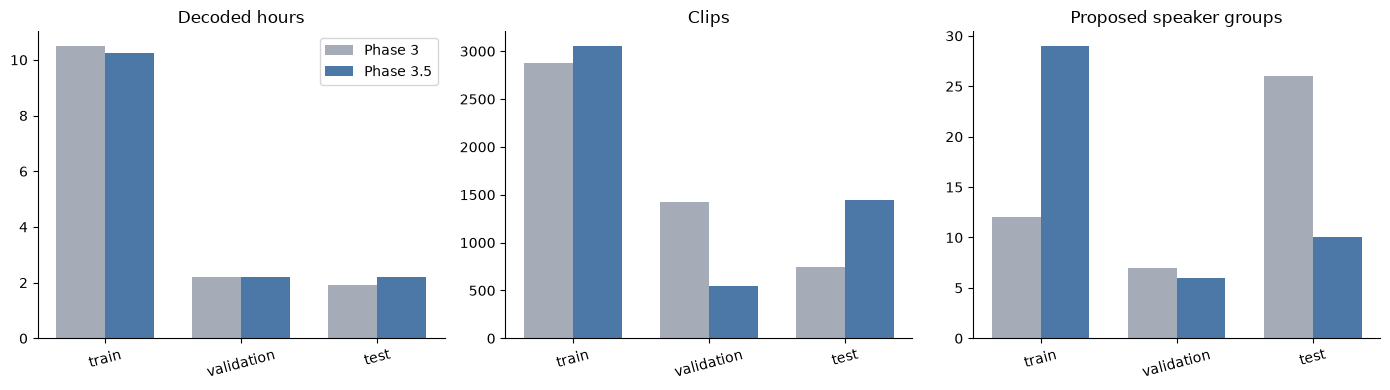

In [6]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Matplotlib is unavailable. Run %pip install matplotlib in a separate cell.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, measure, title in zip(
        axes, ("hours", "clips", "speaker_groups"),
        ("Decoded hours", "Clips", "Proposed speaker groups"),
    ):
        xs = np.arange(3)
        ax.bar(xs - 0.18, old_summary[measure], width=0.36,
               label="Phase 3", color="#a5acb7")
        ax.bar(xs + 0.18, new_summary[measure], width=0.36,
               label="Phase 3.5", color="#4c78a8")
        ax.set_xticks(xs, split_names, rotation=15)
        ax.set_title(title)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend()
    fig.tight_layout()
    plt.show()

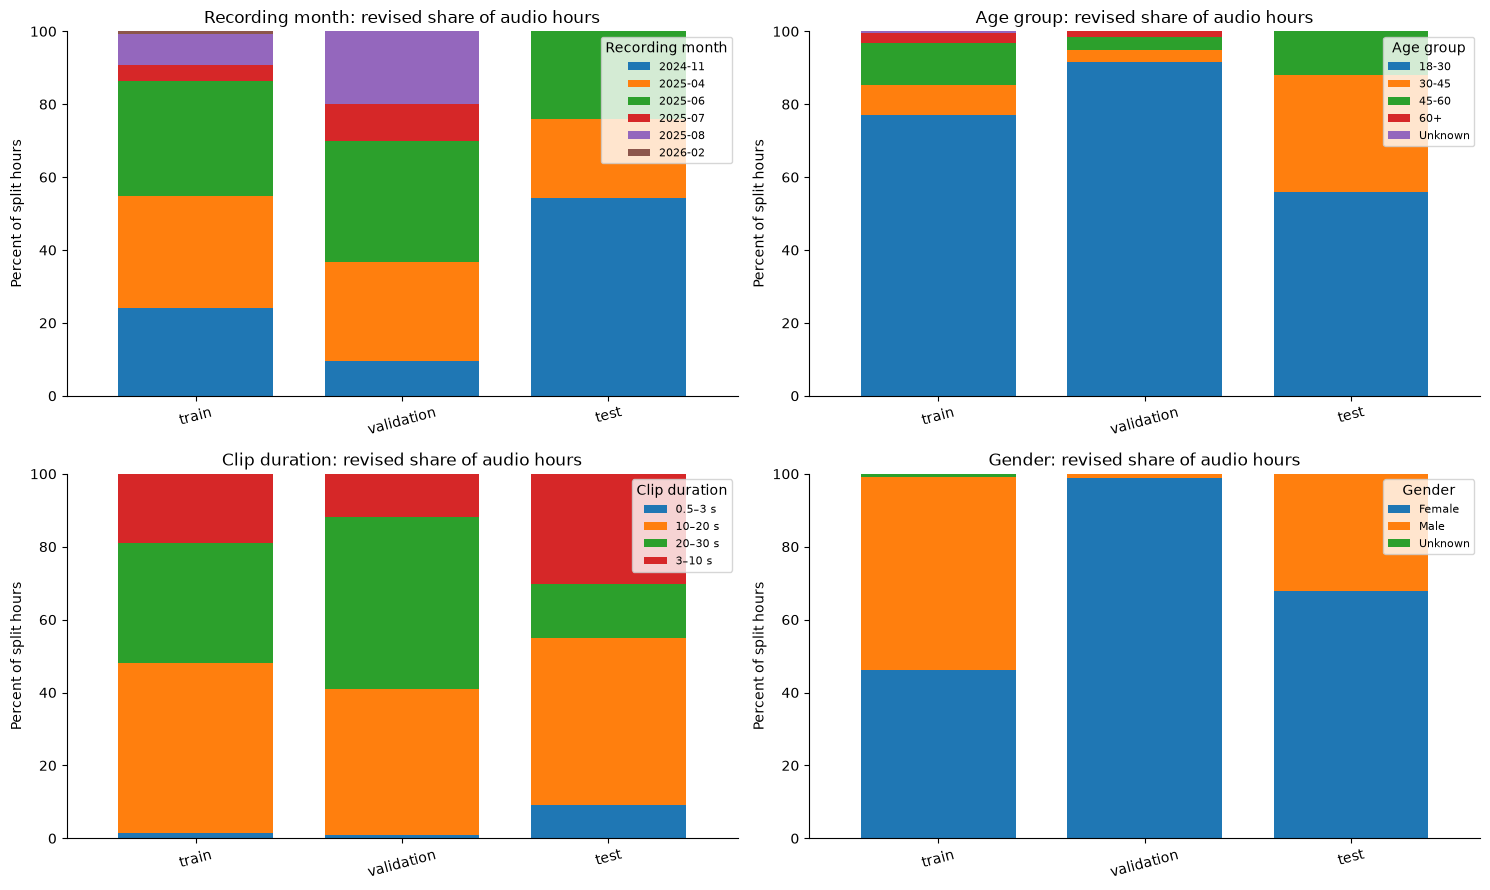

In [7]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Matplotlib is unavailable; category plots skipped.")
else:
    fig, axes = plt.subplots(2, 2, figsize=(15, 9))
    for ax, category, title in zip(
        axes.flat,
        ("recording_month", "age_group", "duration_band", "gender"),
        ("Recording month", "Age group", "Clip duration", "Gender"),
    ):
        table = category_percent("revised_split", category)
        table.plot(kind="bar", stacked=True, ax=ax, width=0.75)
        ax.set_title(title + ": revised share of audio hours")
        ax.set_xlabel("")
        ax.set_ylabel("Percent of split hours")
        ax.set_ylim(0, 100)
        ax.tick_params(axis="x", rotation=15)
        ax.legend(title=title, fontsize=8, loc="upper right")
        ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    plt.show()

## 6. Repeat the structural leakage audit

The new assignment must keep all connected components, public/raw speaker IDs, proposed speaker groups, recording sessions and exact waveforms in one partition. Count exact repeated transcript strings separately. A single shared prompt is a content-overlap diagnostic, not an audio duplicate.

In [8]:
def cross_split_keys(key):
    return int(data.groupby(key, dropna=False)["revised_split"]
               .nunique().gt(1).sum())

overlap = {
    "component": cross_split_keys("component_id"),
    "speaker_group": cross_split_keys("speaker_group_id"),
    "speaker_id": cross_split_keys("speaker_id"),
    "raw_speaker_id": cross_split_keys("speaker_id_raw"),
    "recording_session": cross_split_keys("recording_session_id"),
    "exact_waveform": cross_split_keys("exact_waveform_sha256"),
    "exact_transcript": cross_split_keys("transcript_phase2"),
}
train_only_in_heldout = int(data.loc[
    data["train_only_effective"].astype(bool), "revised_split"
].ne("train").sum())
print("Cross-split overlap:", overlap)
print("Train-only rows in validation/test:", train_only_in_heldout)
if any(overlap[key] for key in
       ("component", "speaker_group", "speaker_id", "raw_speaker_id",
        "recording_session", "exact_waveform")):
    raise RuntimeError("Known structural leakage found; do not save or freeze.")
if train_only_in_heldout:
    raise RuntimeError("Train-only records entered a held-out split.")
if (new_summary.loc[["validation", "test"], "clips"] == 0).any():
    raise RuntimeError("A held-out split is empty.")

Cross-split overlap: {'component': 0, 'speaker_group': 0, 'speaker_id': 0, 'raw_speaker_id': 0, 'recording_session': 0, 'exact_waveform': 0, 'exact_transcript': 1}
Train-only rows in validation/test: 0


## 7. Save the new local proposal and comparison

This cell saves a versioned proposal, summary, and audit with the objective weights and source hash. It does not freeze the split. Keep the row-level manifest local; it contains transcripts and speaker metadata.

In [9]:
run_id = datetime.now().astimezone().strftime("%Y%m%d_%H%M%S")
output_dir = project / "outputs" / f"phase3_5_{run_id}"
output_dir.mkdir(parents=True, exist_ok=False)
revised_path = output_dir / "revised_split_proposal.parquet"
comparison_path = output_dir / "split_comparison.csv"
report_path = output_dir / "audit.json"

data.to_parquet(revised_path, index=False)
comparison = pd.concat(
    {"Phase 3": old_summary, "Phase 3.5": new_summary},
    names=["proposal", "split"],
)
comparison.to_csv(comparison_path)

report = {
    "phase": "3.5",
    "status": "proposed_not_frozen",
    "created_at": datetime.now().astimezone().isoformat(timespec="seconds"),
    "source": str(proposal_path.relative_to(project)),
    "source_sha256": source_sha256,
    "seed": SEED,
    "restarts": RESTARTS,
    "steps_per_restart": STEPS_PER_RESTART,
    "target_share": TARGET_SHARE.tolist(),
    "weights": WEIGHTS,
    "old_score": old_score,
    "new_score": best_score,
    "overlap": overlap,
    "train_only_in_heldout": train_only_in_heldout,
    "source_exact_waveform_audit_reused": True,
    "freeze_approved": False,
}
report_path.write_text(json.dumps(report, ensure_ascii=False, indent=2) + "\n",
                       encoding="utf-8")
if sha256_file(proposal_path) != source_sha256:
    raise RuntimeError("Phase 3 source changed during this run.")
print("New proposal:", revised_path)
print("Proposal SHA-256:", sha256_file(revised_path))
print("Status: proposed, not frozen.")

New proposal: /Users/kanchanpotdar/Downloads/BTP/outputs/phase3_5_20261031_224609/revised_split_proposal.parquet
Proposal SHA-256: 51f505d5be8a9377954a950b1db8d305ca692a214ff1984e759291b2908a46dd
Status: proposed, not frozen.


## 8. Manual decision and optional freeze

Inspect the old/revised comparison, especially whether November 2024 and older age groups appear reasonably in training, validation and test, and whether the validation duration profile is usable for checkpoint selection. Perfect balance may be impossible. Record any residual demographic or recording-period differences in the thesis.

Only after approving the proposal should you change the switch in the next cell to `True`. It creates a frozen manifest in the same output directory and adds its hash to the audit.

In [10]:
APPROVE_FREEZE = False  # Change only after reviewing all tables and plots.

if not APPROVE_FREEZE:
    print("Phase 3.5 proposal is not frozen.")
else:
    if any(overlap[key] for key in
           ("component", "speaker_group", "speaker_id", "raw_speaker_id",
            "recording_session", "exact_waveform")):
        raise RuntimeError("Cannot freeze a proposal with structural leakage.")
    if train_only_in_heldout:
        raise RuntimeError("Cannot freeze train-only examples in held-out sets.")
    frozen_path = output_dir / "frozen_split.parquet"
    if frozen_path.exists():
        raise FileExistsError(frozen_path)
    frozen = data.rename(columns={"revised_split": "final_split"}).copy()
    frozen.to_parquet(frozen_path, index=False)
    report["status"] = "frozen"
    report["freeze_approved"] = True
    report["frozen_sha256"] = sha256_file(frozen_path)
    report_path.write_text(
        json.dumps(report, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
    print("Frozen split:", frozen_path)
    print("SHA-256:", report["frozen_sha256"])

Phase 3.5 proposal is not frozen.


## Phase 3.5 conclusion

**Status: Revised split proposed and audited; not frozen.**

- The comparison uses the same 5,044 clips, approximately 14.625 decoded hours, and 44 indivisible speaker/session/audio components as Phase 3. No model predictions or accuracy results were used to choose the proposal.
- Phase 3.5 proposes train: 3,055 clips / 10.235 hours / 28 components; validation: 542 clips / 2.203 hours / 6 components; test: 1,447 clips / 2.187 hours / 10 components. These hours are closer to the 70/15/15 target than Phase 3.
- The test recording-month mix improved: November 2024 is 54.3% of test hours, compared with 96.4% in Phase 3. Training also contains more public speaker IDs: 32 instead of 14.
- The revised validation set has a serious concentration problem. One component supplies 1.993 of its 2.203 hours (about 90.5%), and 98.8% of validation hours are labelled female. A validation score would be strongly influenced by that one component.
- The revised test set contains 52.3% clips shorter than 3 seconds by clip count, compared with 21.2% in the Phase 3 test set. Duration balance measured by audio hours alone hid this difference.
- Both proposals have zero measured cross-split overlap for connected components, speaker IDs, proposed groups, sessions, and exact decoded waveforms. No train-only clip entered validation or test. One exact transcript crosses splits; this is prompt overlap, not duplicate audio.
- The weighted search score improved from 3.475 to 1.258 under the recorded weights. This score describes the chosen balancing objective; it is not a model metric and does not override the validation-concentration finding.
- **Decision:** Use Phase 3.5 as the starting point for another group-level proposal, but do not freeze it. Add a maximum share per held-out component, inspect gender and recording-month coverage, and compare duration bands by clip count as well as hours. Re-run all leakage checks before approving one final split.
- The saved manifest remains a proposal. Phase 4 processor and tokenizer checks can begin, but model evaluation and training should wait for a frozen split.